In [5]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511039/src/

Mounted at /content/drive
/content/drive/MyDrive/simuteh-2330511039/src


In [ ]:
# Kode 3.1 Statistik dan histogram untuk diagnosis

teh_041.png {'rerata': 167.8, 'simpangan_baku': 37.1, 'min': 71, 'maks': 210, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_042.png {'rerata': 133.5, 'simpangan_baku': 45.7, 'min': 0, 'maks': 198, 'persen_gelap': 8.2, 'persen_terang': 0.0}
teh_043.png {'rerata': 213.1, 'simpangan_baku': 26.5, 'min': 126, 'maks': 254, 'persen_gelap': 0.0, 'persen_terang': 77.6}
teh_044.png {'rerata': 157.9, 'simpangan_baku': 17.2, 'min': 91, 'maks': 205, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 128.3, 'simpangan_baku': 59.3, 'min': 20, 'maks': 251, 'persen_gelap': 1.9, 'persen_terang': 17.2}


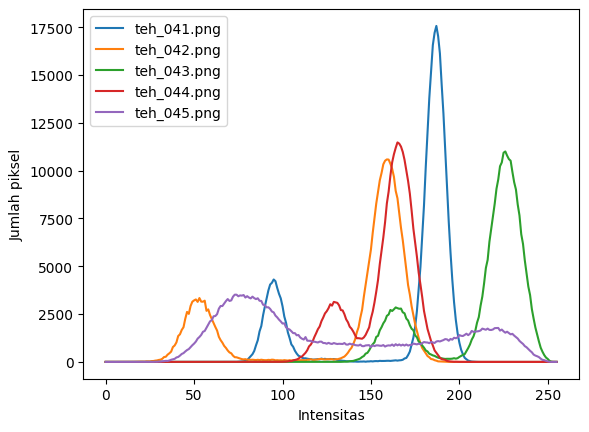

In [6]:
from utils_cv import statistik
for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
 "teh_044.png", "teh_045.png"]:
 gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"),
 cv2.COLOR_BGR2GRAY)
 print(nama, statistik(gray))
 hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
 plt.plot(hist, label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png")

In [ ]:
# hitung statistik
# dan histogram lima citra kondisi berbeda, lalu lakukan hal yang sama untuk lima citra kelas ringan (teh_021 sampai teh_025).

teh_021.png {'rerata': 179.2, 'simpangan_baku': 42.6, 'min': 78, 'maks': 231, 'persen_gelap': 0.0, 'persen_terang': 32.3}
teh_022.png {'rerata': 115.8, 'simpangan_baku': 41.6, 'min': 17, 'maks': 171, 'persen_gelap': 19.7, 'persen_terang': 0.0}
teh_023.png {'rerata': 209.7, 'simpangan_baku': 25.4, 'min': 131, 'maks': 254, 'persen_gelap': 0.0, 'persen_terang': 72.0}
teh_024.png {'rerata': 157.1, 'simpangan_baku': 17.3, 'min': 93, 'maks': 203, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025.png {'rerata': 123.4, 'simpangan_baku': 56.3, 'min': 24, 'maks': 240, 'persen_gelap': 3.3, 'persen_terang': 9.7}


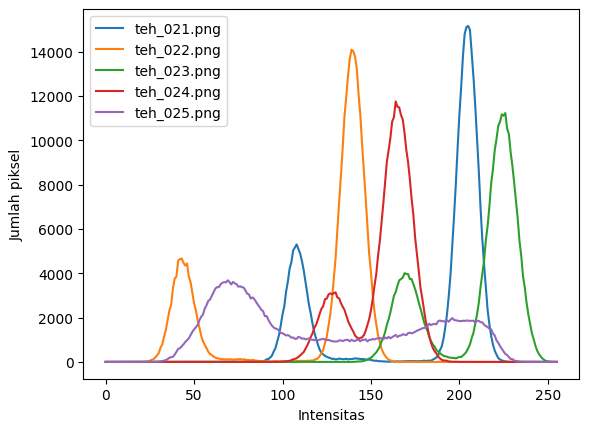

In [9]:
for nama in ["teh_021.png", "teh_022.png", "teh_023.png",
             "teh_024.png", "teh_025.png"]:
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"),
                        cv2.COLOR_BGR2GRAY)
    print(nama, statistik(gray))
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.show()

In [ ]:
# Kode 3.2 Operasi titik, peregangan, gamma, ekualisasi, dan CLAHE

In [8]:
from utils_cv import kontras_bercak # Impor fungsi yang kurang

nama = "teh_045.png" # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
def gamma_lut(g):
 lut = np.array([255 * (i / 255) ** g for i in range(256)])
 return lut.clip(0, 255).astype(np.uint8)
rmin, rmax = np.percentile(gray, (2, 98)) # abaikan 2% piksel ekstrem
hasil = {
 "asli": gray,
 "negatif": 255 - gray,
 "cerah+50": cv2.add(gray, 50),
 "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
 "regang": np.clip((gray - rmin) / (rmax - rmin) * 255,
 0, 255).astype(np.uint8),
 "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
 "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
 "ekualisasi": cv2.equalizeHist(gray),
 "CLAHE": cv2.createCLAHE(clipLimit=2.0,
 tileGridSize=(8, 8)).apply(gray),
}
for nm, c in hasil.items():
 print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} "
 f"sigma={c.std():.1f}")

asli       KB=1.62 sigma=59.3
negatif    KB=1.62 sigma=59.3
cerah+50   KB=1.62 sigma=54.7
kontras    KB=1.62 sigma=78.6
regang     KB=1.68 sigma=81.3
gamma0.5   KB=1.41 sigma=41.5
gamma1.8   KB=2.00 sigma=66.8
ekualisasi KB=1.23 sigma=73.4
CLAHE      KB=2.09 sigma=49.3


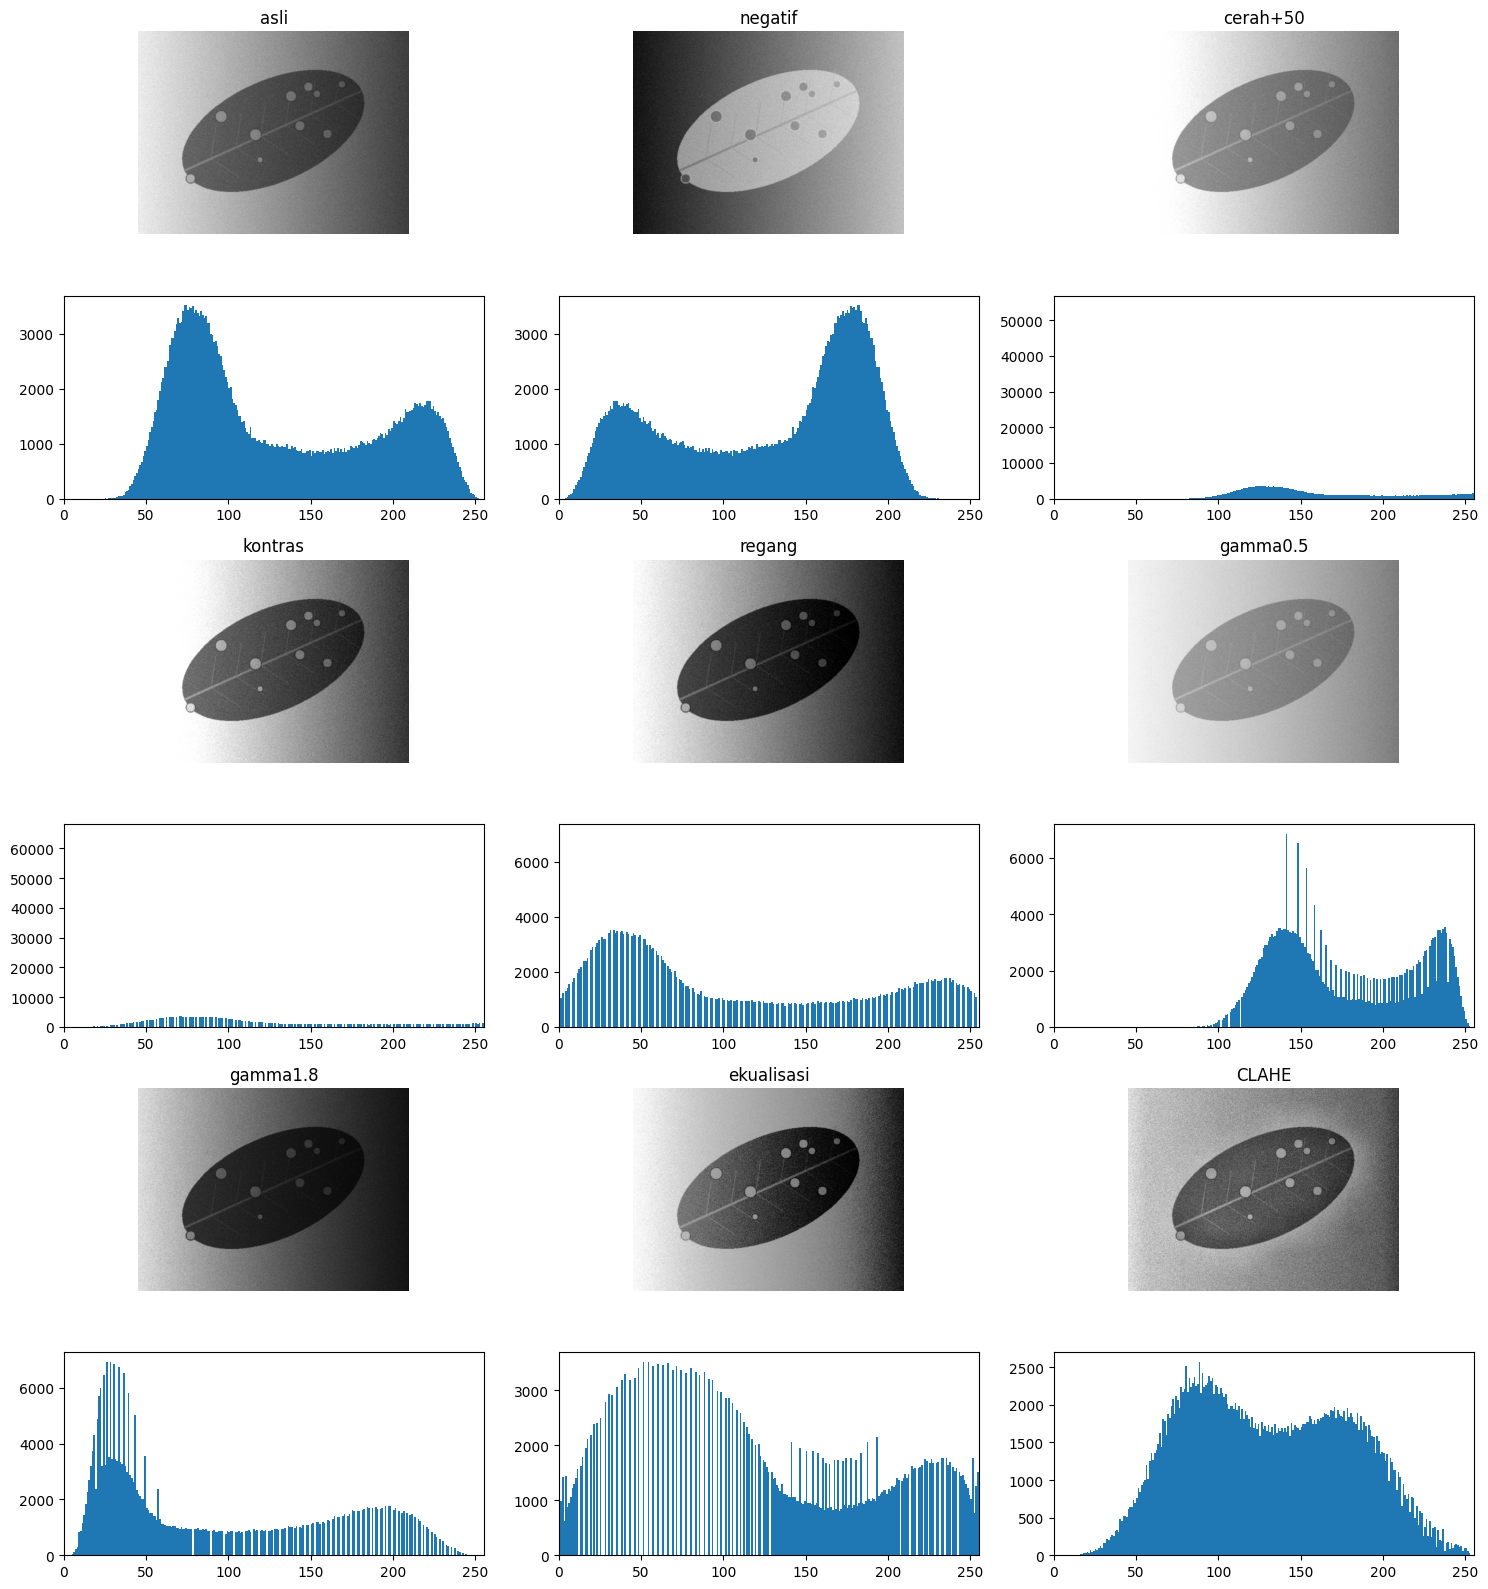

In [10]:
fig, axes = plt.subplots(6, 3, figsize=(15, 16))
for i, (nm, c) in enumerate(hasil.items()):
    kolom = i % 3
    baris = (i // 3) * 2
    ax_img = axes[baris][kolom]
    ax_h = axes[baris + 1][kolom]
    ax_img.imshow(c, cmap="gray", vmin=0, vmax=255)
    ax_img.set_title(nm); ax_img.axis("off")
    ax_h.hist(c.ravel(), bins=256, range=(0, 256))
    ax_h.set_xlim(0, 255)
plt.tight_layout()
plt.savefig("../hasil/b3_panel_perbaikan_teh045.png", dpi=80)
plt.show()

In [ ]:
# Kode 3.3 Eksperimen CLAHE

clip=1.0 tile=4: KB=0.32
clip=1.0 tile=8: KB=0.32
clip=1.0 tile=16: KB=0.32
clip=2.0 tile=4: KB=0.30
clip=2.0 tile=8: KB=0.30
clip=2.0 tile=16: KB=0.33
clip=4.0 tile=4: KB=0.24
clip=4.0 tile=8: KB=0.22
clip=4.0 tile=16: KB=0.28


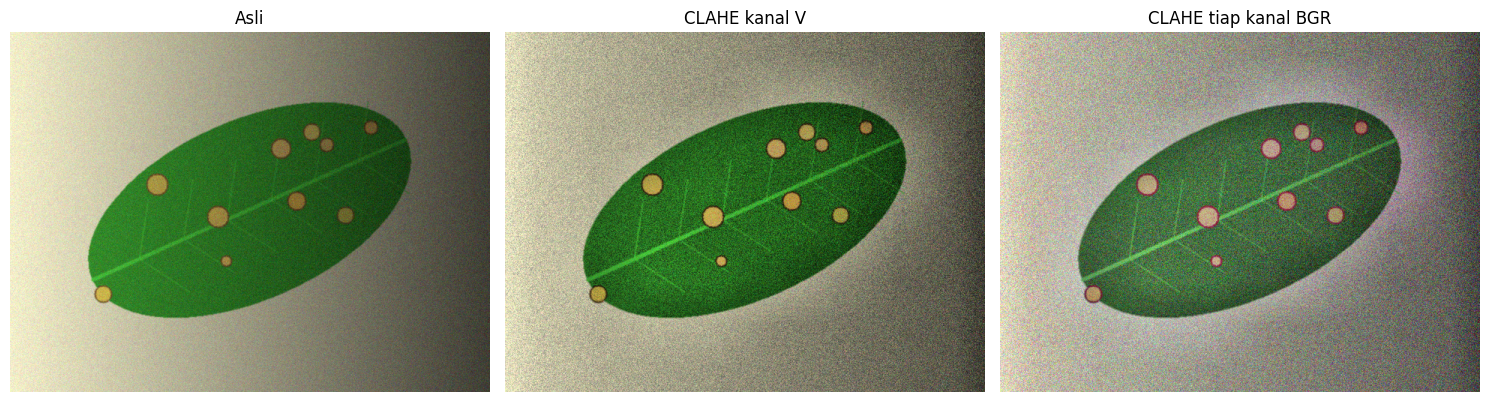

In [20]:
# eksperimen parameter CLAHE
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip,
                            tileGridSize=(tile, tile)).apply(gray)
        print(f"clip={clip} tile={tile}: KB={kontras_bercak(c, md, mb):.2f}")

# CLAHE pada citra warna: kanal V (benar) dan tiap kanal BGR (bandingkan)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])

gelap teh_042.png: KB 3.97 -> 3.21
gelap teh_022.png: KB 2.29 -> 1.73
terang teh_043.png: KB 3.29 -> 3.61
terang teh_023.png: KB 1.93 -> 2.10
kontras_rendah teh_044.png: KB 1.97 -> 2.11
kontras_rendah teh_024.png: KB 1.49 -> 1.61
bayangan teh_045.png: KB 1.62 -> 2.08
bayangan teh_025.png: KB 2.26 -> 1.59


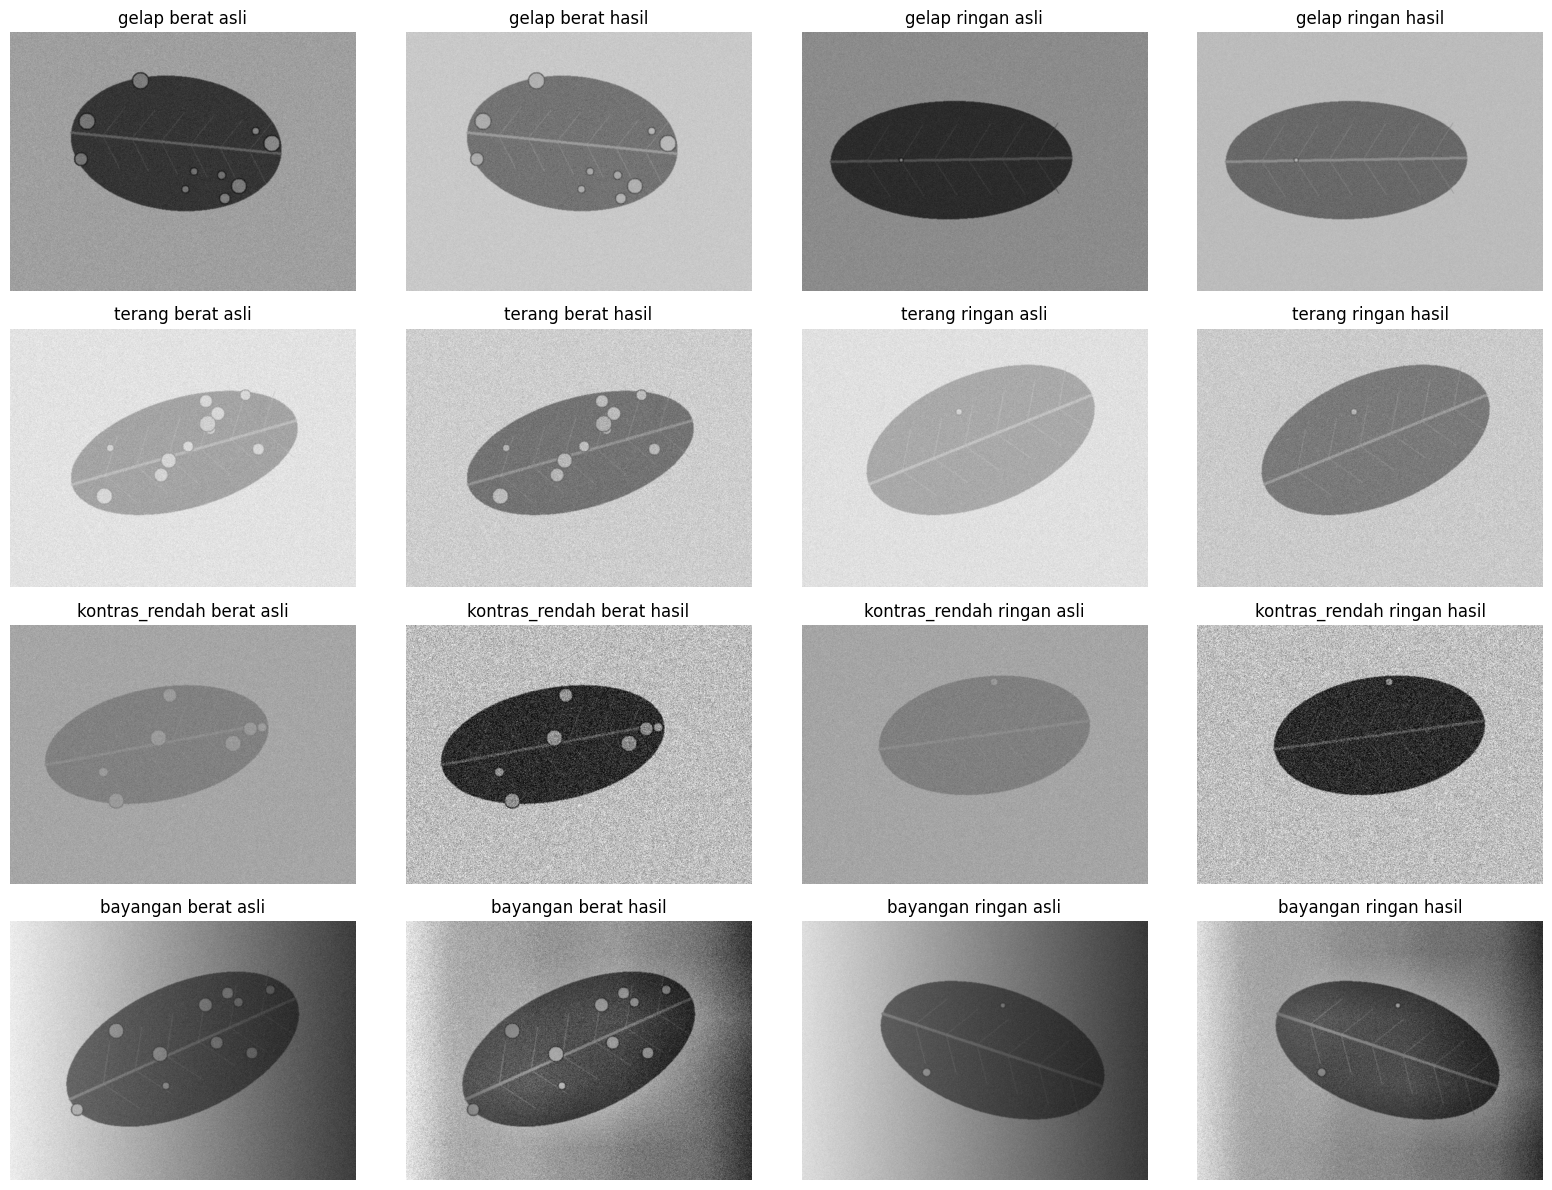

In [21]:
def perbaiki(kondisi, gray):
    if kondisi == "gelap":
        return cv2.LUT(gray, gamma_lut(0.5))
    if kondisi == "terang":
        return cv2.LUT(gray, gamma_lut(1.8))
    if kondisi == "kontras_rendah":
        rmin, rmax = np.percentile(gray, (2, 98))
        return np.clip((gray - rmin) / (rmax - rmin) * 255,
                       0, 255).astype(np.uint8)
    if kondisi == "bayangan":
        return cv2.createCLAHE(clipLimit=2.0,
                               tileGridSize=(4, 4)).apply(gray)

pasangan = {"gelap": ("teh_042.png", "teh_022.png"),
            "terang": ("teh_043.png", "teh_023.png"),
            "kontras_rendah": ("teh_044.png", "teh_024.png"),
            "bayangan": ("teh_045.png", "teh_025.png")}

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
label = ["berat asli", "berat hasil", "ringan asli", "ringan hasil"]
for baris, (kondisi, (fb, fr)) in enumerate(pasangan.items()):
    citra = []
    for f in (fb, fr):
        imgx = baca(f"../data/sintetis/citra/{f}")
        mdx = cv2.imread(f"../data/sintetis/mask_daun/{f}", 0)
        mbx = cv2.imread(f"../data/sintetis/mask_bercak/{f}", 0)
        grayx = cv2.cvtColor(imgx, cv2.COLOR_BGR2GRAY)
        hasilx = perbaiki(kondisi, grayx)
        print(f"{kondisi} {f}: KB {kontras_bercak(grayx, mdx, mbx):.2f} "
              f"-> {kontras_bercak(hasilx, mdx, mbx):.2f}")
        citra += [grayx, hasilx]
    for kolom, c in enumerate(citra):
        axes[baris][kolom].imshow(c, cmap="gray", vmin=0, vmax=255)
        axes[baris][kolom].set_title(f"{kondisi} {label[kolom]}")
        axes[baris][kolom].axis("off")
plt.tight_layout()
plt.savefig("../hasil/b3_panel_perbaikan_4kondisi.png", dpi=80)
plt.show()